# Klasifikasi Biner Risiko Gagal Jantung Berdasarkan Data Klinis Pasien Menggunakan Decision Tree

UTS Pembelajaran Mesin. Dataset: [Heart Failure Prediction (Kaggle)](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction).

**Alur:** setup, EDA, preprocessing, pelatihan dengan GridSearchCV, evaluasi, interpretasi pohon, lalu simpan model untuk aplikasi Flask.

## 1. Setup

Versi scikit-learn dipasang sama dengan lingkungan aplikasi Flask (Python 3.10) supaya `model.joblib` kompatibel. **Setelah sel ini selesai, wajib klik Runtime > Restart session**, lalu lanjut dari sel import di bawahnya (jangan jalankan ulang sel pip).

In [1]:
%pip install -q scikit-learn==1.7.2

In [2]:
import json
import os
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")
SEED = 42
print("scikit-learn:", sklearn.__version__)
if sklearn.__version__ != "1.7.2":
    print("PERINGATAN: versi harus 1.7.2. Klik Runtime > Restart session, lalu jalankan ulang dari sel import ini.")

scikit-learn: 1.7.2


## 2. Memuat Data

Upload `heart.csv` lewat panel Files di sisi kiri Colab (ikon folder), sehingga berada di `/content/heart.csv`.

In [3]:
df = pd.read_csv("heart.csv")
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Exploratory Data Analysis (EDA)

In [4]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


In [5]:
print("Missing value :", df.isna().sum().sum())
print("Baris duplikat:", df.duplicated().sum())
print("RestingBP == 0 :", (df["RestingBP"] == 0).sum(), "baris")
print("Cholesterol == 0:", (df["Cholesterol"] == 0).sum(), "baris")

Missing value : 0
Baris duplikat: 0
RestingBP == 0 : 1 baris
Cholesterol == 0: 172 baris


Tidak ada nilai kosong, tetapi ada nilai 0 yang tidak masuk akal secara medis: tekanan darah 0 (1 baris) dan kolesterol 0 (banyak baris). Nilai ini diperlakukan sebagai data tidak tercatat pada tahap preprocessing.

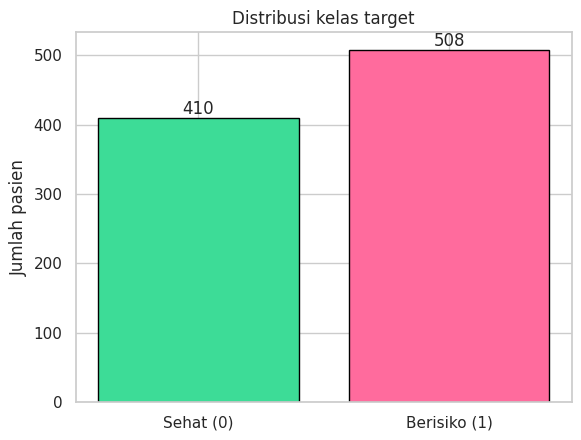

HeartDisease
0    44.7
1    55.3
Name: count, dtype: float64


In [6]:
counts = df["HeartDisease"].value_counts().sort_index()
bars = plt.bar(["Sehat (0)", "Berisiko (1)"], counts.values, color=["#3ddc97", "#ff6b9d"], edgecolor="black")
plt.bar_label(bars)
plt.title("Distribusi kelas target"); plt.ylabel("Jumlah pasien"); plt.show()
print((counts / len(df) * 100).round(1))

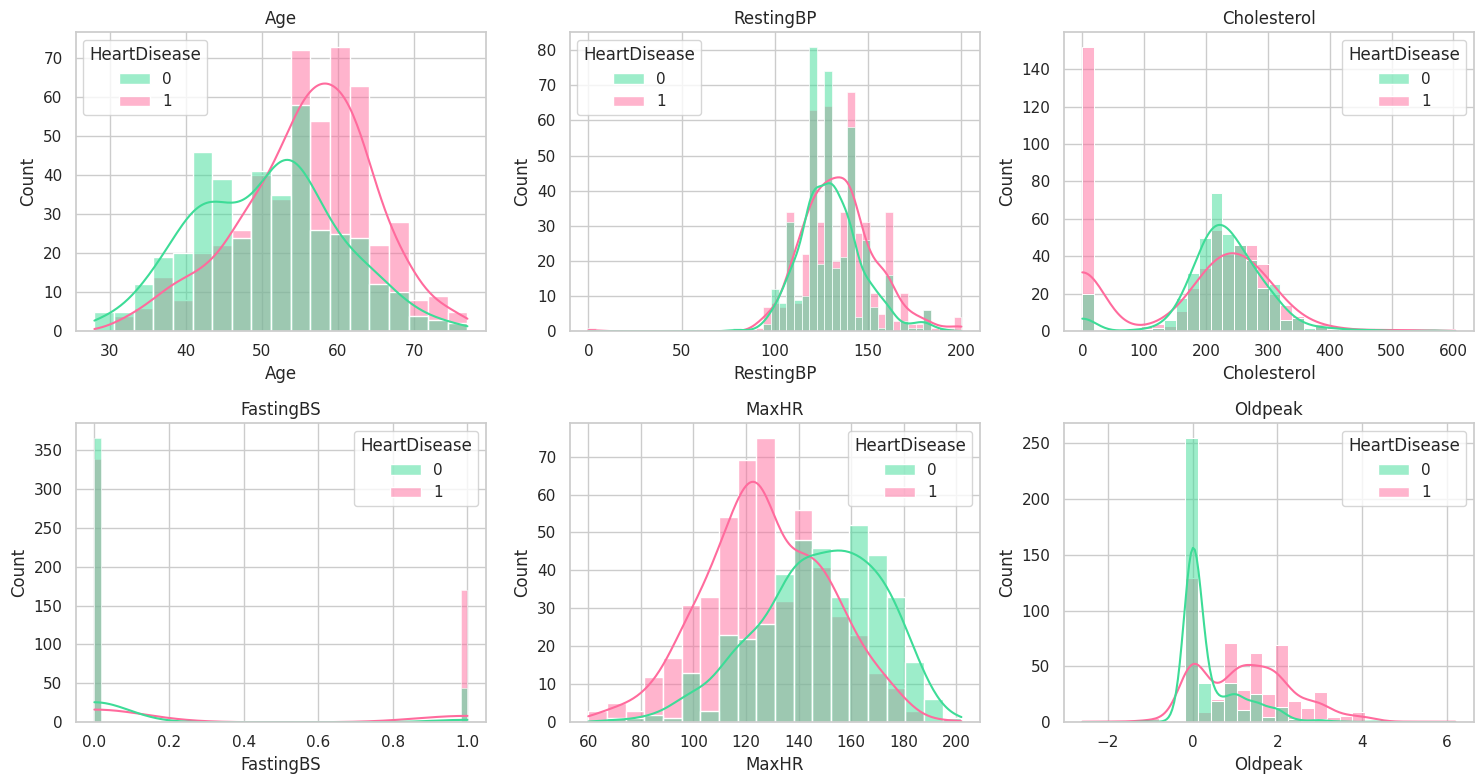

In [7]:
NUMERIC = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"]
CATEGORICAL = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
TARGET = "HeartDisease"

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, palette=["#3ddc97", "#ff6b9d"], ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

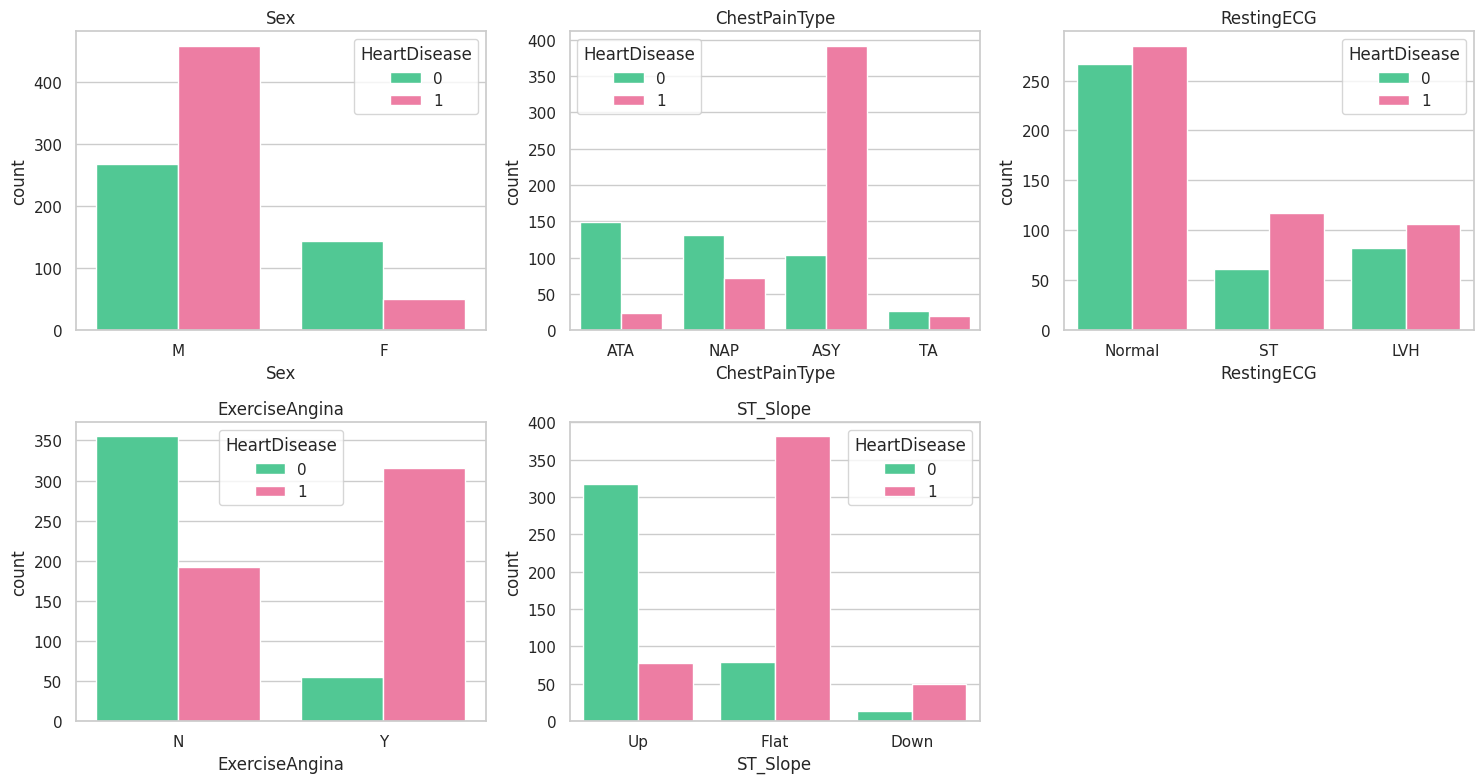

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), CATEGORICAL):
    sns.countplot(data=df, x=col, hue=TARGET, palette=["#3ddc97", "#ff6b9d"], ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

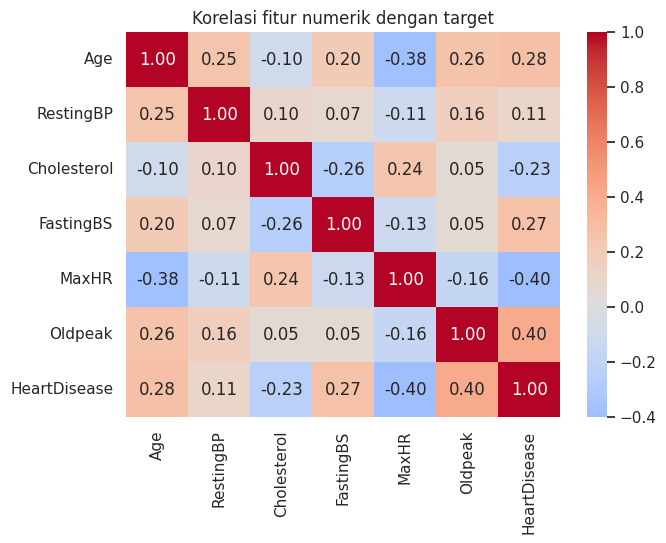

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[NUMERIC + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi fitur numerik dengan target"); plt.show()

## 4. Preprocessing

- 1 baris `RestingBP = 0` dibuang.
- `Cholesterol = 0` diubah menjadi NaN lalu diisi median (di dalam pipeline, agar median hanya dihitung dari data latih).
- Fitur kategorikal di-one-hot encoding. Decision Tree tidak membutuhkan scaling.
- Data dibagi 80:20 dengan stratifikasi.

In [10]:
data = df[df["RestingBP"] > 0].copy()
data["Cholesterol"] = data["Cholesterol"].replace(0, np.nan)

X, y = data[NUMERIC + CATEGORICAL], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)


def build_pipeline(**tree_params):
    prep = ColumnTransformer(
        [("num", SimpleImputer(strategy="median"), NUMERIC),
         ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)],
        sparse_threshold=0,
    )
    return Pipeline([("prep", prep), ("tree", DecisionTreeClassifier(random_state=SEED, **tree_params))])

Train: (733, 11) | Test: (184, 11)


## 5. Pelatihan dengan GridSearchCV

Parameter dicari dengan validasi silang 5 lipatan pada data latih, dengan skor F1.

In [11]:
grid = GridSearchCV(
    build_pipeline(),
    {"tree__max_depth": [2, 3, 4, 5, 6, 7, 8],
     "tree__criterion": ["gini", "entropy"],
     "tree__min_samples_leaf": [1, 5, 10, 20]},
    scoring="f1", cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

model = grid.best_estimator_
print("Parameter terbaik:", grid.best_params_)
print("F1 validasi silang:", round(grid.best_score_, 4))

Parameter terbaik: {'tree__criterion': 'gini', 'tree__max_depth': 3, 'tree__min_samples_leaf': 20}
F1 validasi silang: 0.8578


## 6. Evaluasi pada Data Uji

In [12]:
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
scores = {
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "f1": f1_score(y_test, pred),
    "auc": roc_auc_score(y_test, proba),
}
print(pd.Series(scores).round(4))
print()
print(classification_report(y_test, pred, target_names=["Sehat", "Berisiko"]))

accuracy     0.8315
precision    0.8660
recall       0.8235
f1           0.8442
auc          0.8964
dtype: float64

              precision    recall  f1-score   support

       Sehat       0.79      0.84      0.82        82
    Berisiko       0.87      0.82      0.84       102

    accuracy                           0.83       184
   macro avg       0.83      0.83      0.83       184
weighted avg       0.83      0.83      0.83       184



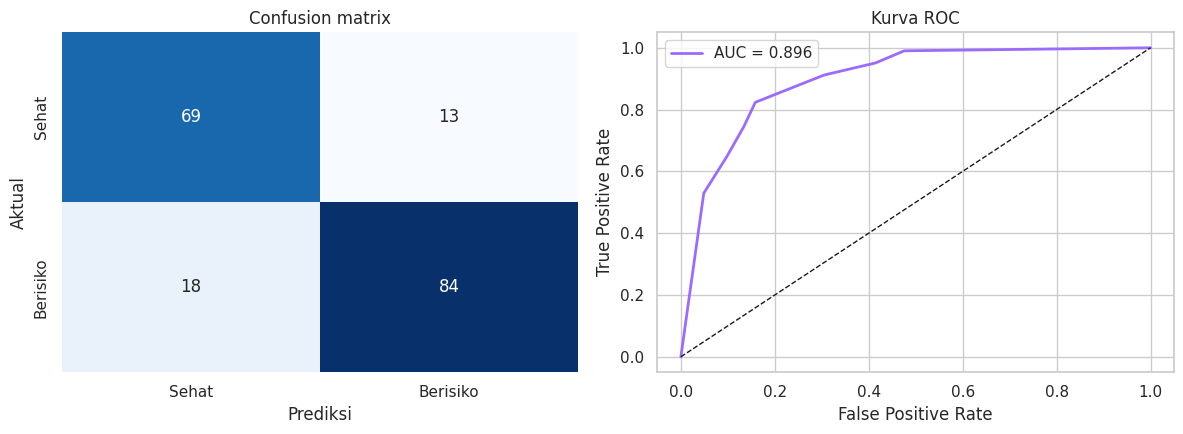

In [13]:
cm = confusion_matrix(y_test, pred)
fpr, tpr, _ = roc_curve(y_test, proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Sehat", "Berisiko"], yticklabels=["Sehat", "Berisiko"])
axes[0].set(title="Confusion matrix", xlabel="Prediksi", ylabel="Aktual")
axes[1].plot(fpr, tpr, color="#9b6bff", lw=2, label=f"AUC = {scores['auc']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set(title="Kurva ROC", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[1].legend(); plt.tight_layout(); plt.show()

Recall penting di kasus ini karena pasien berisiko yang tidak terdeteksi (False Negative) lebih berbahaya daripada pasien sehat yang salah ditandai berisiko.

## 7. Pengaruh `max_depth`

Parameter lain mengikuti model terbaik. Jika akurasi mendatar setelah kedalaman tertentu, itu karena `min_samples_leaf` membatasi pohon berhenti tumbuh.

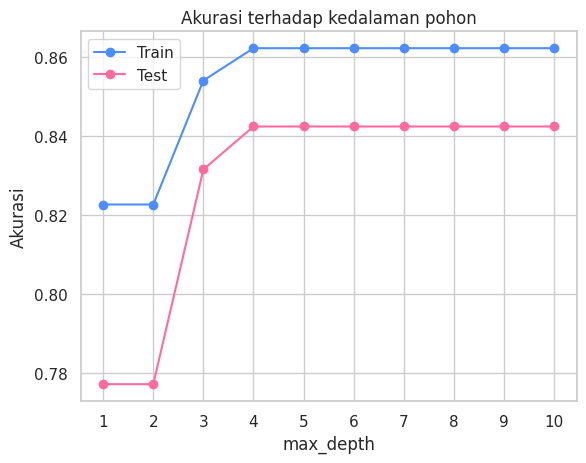

,depth,train,test
0,1,0.8226,0.7772
1,2,0.8226,0.7772
2,3,0.8540,0.8315
3,4,0.8622,0.8424
4,5,0.8622,0.8424
5,6,0.8622,0.8424
6,7,0.8622,0.8424
7,8,0.8622,0.8424
8,9,0.8622,0.8424
9,10,0.8622,0.8424


In [14]:
best = {k.split("__")[1]: v for k, v in grid.best_params_.items() if k != "tree__max_depth"}
depth_curve = []
for depth in range(1, 11):
    m = build_pipeline(max_depth=depth, **best).fit(X_train, y_train)
    depth_curve.append({"depth": depth, "train": m.score(X_train, y_train), "test": m.score(X_test, y_test)})

curve = pd.DataFrame(depth_curve)
plt.plot(curve["depth"], curve["train"], "o-", label="Train", color="#4d8dff")
plt.plot(curve["depth"], curve["test"], "o-", label="Test", color="#ff6b9d")
plt.xticks(curve["depth"]); plt.xlabel("max_depth"); plt.ylabel("Akurasi")
plt.title("Akurasi terhadap kedalaman pohon"); plt.legend(); plt.show()
curve.round(4)

## 8. Interpretasi Model

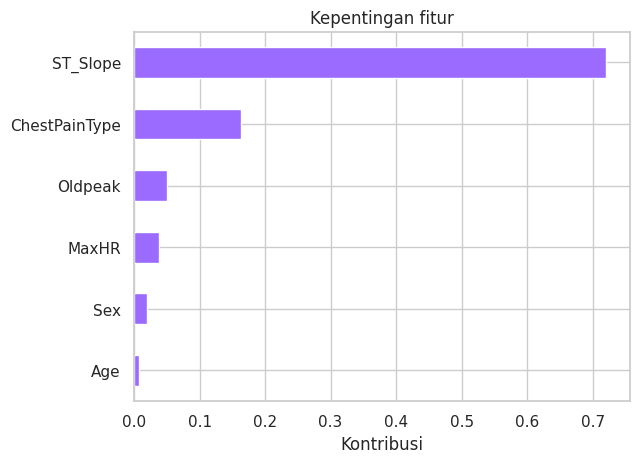

In [15]:
names = model.named_steps["prep"].get_feature_names_out()
importance = {}
for name, value in zip(names, model.named_steps["tree"].feature_importances_):
    col = name.split("__")[1]
    col = col.rsplit("_", 1)[0] if name.startswith("cat__") else col
    importance[col] = importance.get(col, 0) + float(value)
importance = dict(sorted(importance.items(), key=lambda kv: -kv[1]))

imp = pd.Series(importance)
imp[imp > 0].sort_values().plot.barh(color="#9b6bff")
plt.title("Kepentingan fitur"); plt.xlabel("Kontribusi"); plt.show()

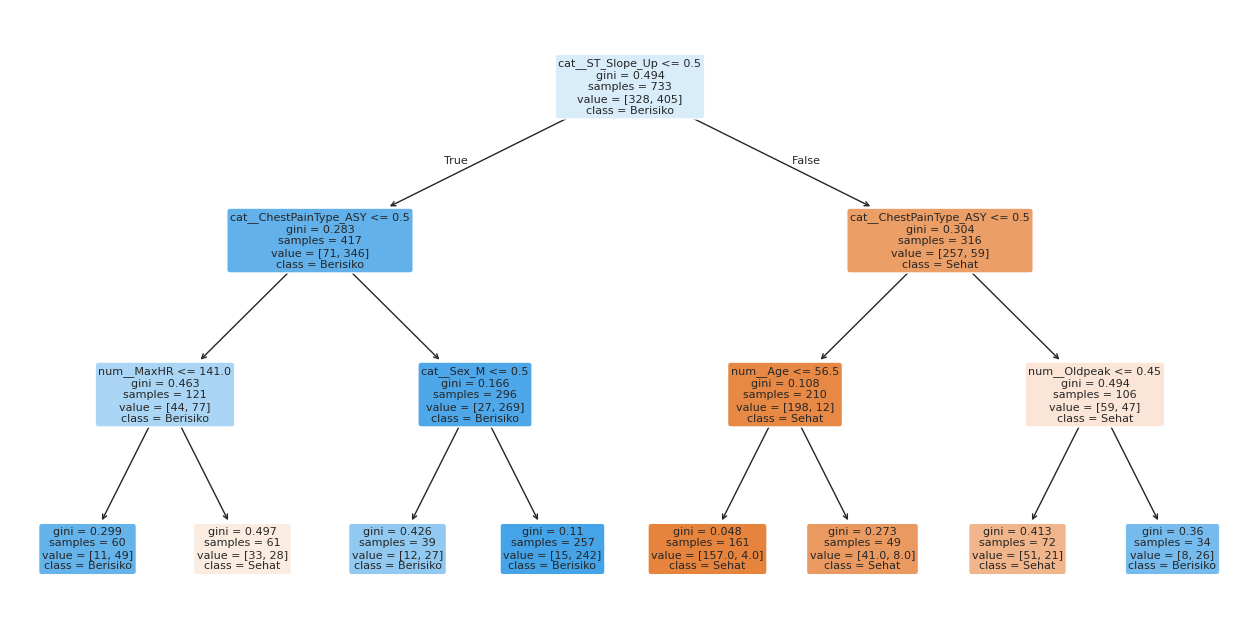

In [16]:
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(model.named_steps["tree"], feature_names=list(names), class_names=["Sehat", "Berisiko"],
          filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax)
plt.show()

## 9. Simpan Model untuk Aplikasi Flask

Menghasilkan `model.joblib`, `metrics.json`, dan grafik PNG berpalet biru (confusion matrix, ROC, kepentingan fitur, kurva max_depth, korelasi, distribusi kelas) seperti `train_model.py`, lalu mengunduhnya sebagai zip. Salin `model.joblib` dan `metrics.json` ke folder `model/`, serta isi folder `img/` ke `static/img/` pada proyek Flask.

In [17]:
def save_figures(out, df, numeric, target, y_test, proba, cm, importance, depth_curve):
    """Simpan grafik evaluasi dan EDA (palet biru) sebagai PNG ke folder out."""
    from pathlib import Path

    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.colors import LinearSegmentedColormap
    from sklearn.metrics import roc_auc_score, roc_curve

    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    ink, blue, sky, pink, green = "#111111", "#2f6bff", "#7cc7ff", "#ff5c7c", "#2ed3a0"
    blues = LinearSegmentedColormap.from_list("nb_blue", ["#ffffff", sky, blue])
    diverge = LinearSegmentedColormap.from_list("nb_div", [pink, "#ffffff", blue])
    cm = np.array(cm)
    with plt.style.context("default"):

        def finish(fig, ax, title, name):
            ax.set_title(title, fontsize=13, fontweight="bold", color=ink, pad=12)
            for spine in ax.spines.values():
                spine.set_color(ink)
                spine.set_linewidth(2)
            fig.savefig(out / name, dpi=150, bbox_inches="tight", facecolor="white")
            plt.close(fig)

        fig, ax = plt.subplots(figsize=(5.2, 4.6))
        ax.imshow(cm, cmap=blues)
        ax.grid(False)
        ax.set_xticks([0, 1], ["Sehat", "Berisiko"])
        ax.set_yticks([0, 1], ["Sehat", "Berisiko"])
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, int(cm[i][j]), ha="center", va="center", fontsize=26, fontweight="bold",
                        color="white" if cm[i][j] > cm.max() / 2 else ink)
        finish(fig, ax, "Confusion Matrix", "confusion_matrix.png")

        fpr, tpr, _ = roc_curve(y_test, proba)
        fig, ax = plt.subplots(figsize=(5.2, 4.6))
        ax.fill_between(fpr, tpr, color=sky, alpha=0.35)
        ax.plot(fpr, tpr, color=blue, lw=3, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
        ax.plot([0, 1], [0, 1], "--", color=ink, lw=1.5)
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.legend(loc="lower right", edgecolor=ink)
        finish(fig, ax, "Kurva ROC", "roc_curve.png")

        items = [(k, v) for k, v in importance.items() if v > 0][::-1]
        fig, ax = plt.subplots(figsize=(5.6, 4.2))
        ax.barh([k for k, _ in items], [v * 100 for _, v in items], color=blue, edgecolor=ink, linewidth=2)
        for y, (_, v) in enumerate(items):
            ax.text(v * 100 + 1, y, f"{v * 100:.1f}%", va="center", fontweight="bold")
        ax.set_xlim(0, max(v for _, v in items) * 118)
        ax.set_xlabel("Kontribusi (%)")
        finish(fig, ax, "Kepentingan Fitur", "feature_importance.png")

        depth = [d["depth"] for d in depth_curve]
        fig, ax = plt.subplots(figsize=(5.6, 4.2))
        ax.plot(depth, [d["train"] for d in depth_curve], "o-", color=pink, lw=3, mec=ink, label="Train")
        ax.plot(depth, [d["test"] for d in depth_curve], "o-", color=blue, lw=3, mec=ink, label="Test")
        ax.set_xticks(depth)
        ax.set_xlabel("max_depth")
        ax.set_ylabel("Akurasi")
        ax.grid(alpha=0.25)
        ax.legend(edgecolor=ink)
        finish(fig, ax, "Akurasi terhadap max_depth", "depth_curve.png")

        cols = list(numeric) + [target]
        corr = df[cols].corr()
        fig, ax = plt.subplots(figsize=(6.2, 5.2))
        ax.imshow(corr, cmap=diverge, vmin=-1, vmax=1)
        ax.grid(False)
        ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
        ax.set_yticks(range(len(cols)), cols)
        for i in range(len(cols)):
            for j in range(len(cols)):
                ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=ink)
        finish(fig, ax, "Korelasi Fitur Numerik", "correlation.png")

        counts = df[target].value_counts().sort_index()
        fig, ax = plt.subplots(figsize=(5.2, 4.2))
        bars = ax.bar(["Sehat", "Berisiko"], counts.values, color=[green, pink], edgecolor=ink, linewidth=2)
        ax.bar_label(bars, fontweight="bold", padding=3)
        ax.set_ylim(0, counts.max() * 1.15)
        ax.set_ylabel("Jumlah pasien")
        finish(fig, ax, "Distribusi Kelas Target", "class_distribution.png")


metrics = {
    **scores,
    "cv_f1": grid.best_score_,
    "best_params": {k.split("__")[1]: v for k, v in grid.best_params_.items()},
    "confusion": cm.tolist(),
    "importance": importance,
    "depth_curve": depth_curve,
    "ranges": {c: [float(data[c].min()), float(data[c].max())] for c in NUMERIC},
    "n_total": len(data), "n_train": len(X_train), "n_test": len(X_test),
    "n_positive": int(y.sum()),
    "sklearn_version": sklearn.__version__,
    "medians": {c: float(data[c].median()) for c in NUMERIC},
    "target_corr": {c: float(data[c].corr(data[TARGET])) for c in NUMERIC},
}

os.makedirs("hasil", exist_ok=True)
joblib.dump(model, "hasil/model.joblib")
with open("hasil/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

save_figures("hasil/img", data, NUMERIC, TARGET, y_test, proba, cm, importance, depth_curve)

with zipfile.ZipFile("hasil_training.zip", "w") as z:
    for name in ["model.joblib", "metrics.json"]:
        z.write(f"hasil/{name}", name)
    for png in sorted(os.listdir("hasil/img")):
        z.write(f"hasil/img/{png}", f"img/{png}")

try:
    from google.colab import files
    files.download("hasil_training.zip")
except ImportError:
    print("Selesai. File ada di hasil_training.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Kesimpulan

**Model.** Decision Tree dilatih pada 917 pasien (918 baris dikurangi 1 baris tekanan darah 0) dengan 11 fitur klinis untuk mengklasifikasikan risiko gagal jantung. GridSearchCV 5 lipatan dengan skor F1 memilih `criterion=gini`, `max_depth=3`, dan `min_samples_leaf=20`, dengan F1 validasi silang 85,8%.

**Performa pada 184 data uji.** Accuracy 83,2%, precision 86,6%, recall 82,4%, F1 84,4%, dan AUC 0,896. Confusion matrix menunjukkan 69 True Negative, 84 True Positive, 13 False Positive, dan 18 False Negative. Akurasi latih (85,4%) dan uji (83,2%) hanya berselisih sekitar 2 poin, sehingga tidak ada tanda overfitting.

**Fitur paling menentukan.** ST_Slope (72,1%) dan ChestPainType (16,4%) menentukan 88,5% keputusan pohon. Oldpeak (5,0%), MaxHR (3,8%), Sex (2,0%), dan Age (0,7%) berperan kecil, sedangkan RestingBP, Cholesterol, FastingBS, RestingECG, dan ExerciseAngina tidak dipakai pohon.

**Pengaruh `max_depth`.** Akurasi uji naik dari 77,7% pada depth 1 menjadi 83,2% pada depth 3, lalu mendatar di 84,2% mulai depth 4 karena `min_samples_leaf=20` membatasi pertumbuhan pohon. Depth 3 dipilih lewat validasi silang pada data latih, bukan dari data uji, sehingga dipertahankan sebagai pohon paling sederhana dengan performa yang mendekati terbaik.

**Keterbatasan dan saran.** Masih ada 18 pasien berisiko yang tidak terdeteksi, data hanya berjumlah 917 pasien, dan 172 nilai kolesterol bernilai 0 diperlakukan sebagai data hilang lalu diisi median. Model ini hanya untuk pembelajaran dan bukan alat diagnosis. Pengembangan berikutnya dapat membandingkan dengan Random Forest, menurunkan ambang keputusan di bawah 50% untuk menaikkan recall, atau menguji model pada dataset lain.